# 04 — Extending the models

The plan's comments ask for room to refine each stage. Every stage is a small protocol with a
registry, so a new model is a class plus one registration and is then selectable from YAML.
This notebook shows: a wavelength-dependent sensitivity, a noisy detection model, a confusion
model that depends on signal-to-noise, and a custom line set.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

In [2]:
from romanmock.lines import get_line_set
from romanmock import feature_fluxes, detect_lines, ConstantFluxLimit, TabulatedFluxLimit, ThresholdDetection, GaussianNoiseDetection
from romanmock.io import open_catalog

line_set = get_line_set("roman_transitions")
cat = open_catalog([f"{CATALOG}/lc_cores-219.diffsky_gals.hdf5"])
data = cat.take(200_000, at="start").select(*line_set.required_columns, "redshift_true", "redshift_obs").get_data("numpy", wrap_single=True)
flux = feature_fluxes(data, line_set, data["redshift_true"], cat.cosmology)
z_rsd = data["redshift_obs"]

## Wavelength-dependent sensitivity

`TabulatedFluxLimit` interpolates a flux-limit curve (log-linear) and is infinite outside its
range. Any object with `wave_range` and `flux_limit(wave_obs)` works; register it in
`romanmock.sensitivity.SENSITIVITY_MODELS` to select it by name from YAML (`type: tabulated`,
with `file:` for a two-column text file). A model that also defines `secondary_flux_limit(wave_obs)`
gets the two-tier rule (lower limit for the other lines of a galaxy with one line above `flux_limit`);
`TabulatedFluxLimit` takes it as a ratio, `secondary_ratio=0.4` being the equivalent of 4e-17 at 1e-16.

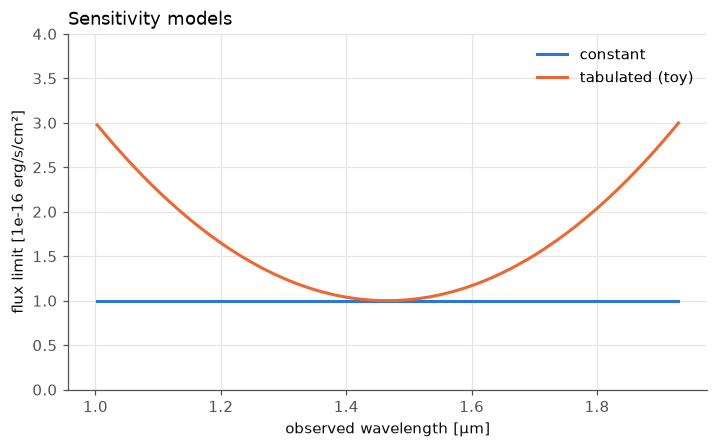

constant   detected fraction (any line): 0.321   multi-line among detected: 0.927
tabulated  detected fraction (any line): 0.320   multi-line among detected: 0.593


In [3]:
wave = np.linspace(10000, 19300, 50)
curve = 1e-16 * (1 + 2.0 * ((wave - 14650) / 4650) ** 2)      # toy: worse sensitivity towards the band edges
tab = TabulatedFluxLimit(wave, curve, secondary_ratio=0.4)      # same two tiers as the constant default (1e-16, 4e-17)

fig, ax = plt.subplots()
w = np.linspace(9500, 20000, 300)
ax.plot(w / 1e4, ConstantFluxLimit(1e-16).flux_limit(w) * 1e16, color=plotting.CATEGORICAL[0], label="constant")
ax.plot(w / 1e4, tab.flux_limit(w) * 1e16, color=plotting.CATEGORICAL[1], label="tabulated (toy)")
ax.set_ylim(0, 4); ax.set_xlabel("observed wavelength [μm]"); ax.set_ylabel("flux limit [1e-16 erg/s/cm²]")
ax.set_title("Sensitivity models"); ax.legend(); plt.show()

for name, model in [("constant", ConstantFluxLimit(1e-16)), ("tabulated", tab)]:
    det = detect_lines(flux, z_rsd, line_set, ThresholdDetection(model))
    print(f"{name:<10s} detected fraction (any line): {np.mean(det.n_det > 0):.3f}   multi-line among detected: "
          f"{np.mean(det.n_det[det.n_det > 0] > 1):.3f}")

## Detection scatter

`GaussianNoiseDetection` adds flux noise `σ = F_lim / snr_at_limit` and detects at
`S/N > snr_threshold`; the detection probability becomes a smooth function of `F / F_lim`.

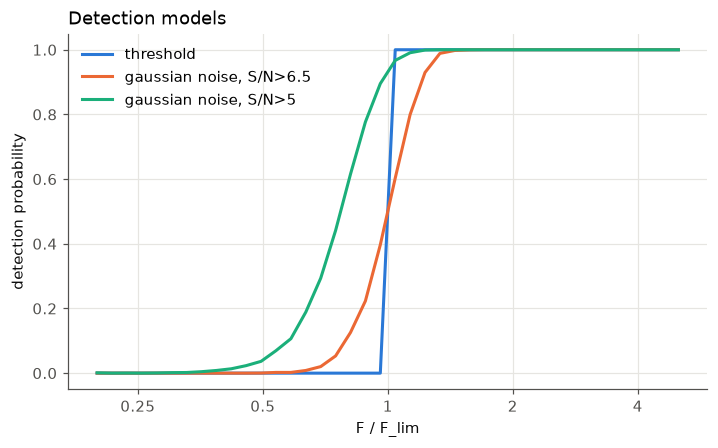

In [4]:
rng = np.random.default_rng(1)
ratio = np.logspace(-0.7, 0.7, 40)
n = 4000
z = np.full(n, 1.2)
probs = {}
for label, model in [("threshold", ThresholdDetection(ConstantFluxLimit(1e-16))),
                     ("gaussian noise, S/N>6.5", GaussianNoiseDetection(ConstantFluxLimit(1e-16), snr_at_limit=6.5, snr_threshold=6.5)),
                     ("gaussian noise, S/N>5", GaussianNoiseDetection(ConstantFluxLimit(1e-16), snr_at_limit=6.5, snr_threshold=5.0))]:
    p = []
    for r in ratio:
        f = np.zeros((n, len(line_set))); f[:, 0] = r * 1e-16
        p.append(detect_lines(f, z, line_set, model, rng).detected[:, 0].mean())
    probs[label] = np.array(p)

fig, ax = plt.subplots()
for (label, p), color in zip(probs.items(), plotting.CATEGORICAL):
    ax.plot(ratio, p, color=color, label=label)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"]); ax.minorticks_off()
ax.set_xlabel("F / F_lim"); ax.set_ylabel("detection probability")
ax.set_title("Detection models"); ax.legend(); plt.show()

## A confusion model that depends on signal-to-noise

`assign(true_index, context, rng)` receives `wave_obs`, `snr`, `flux`, `z_rsd` and any
`redshift.context_columns` from the catalog (photometry, ...). Below, the failure probability
falls with S/N and the remainder is distributed like a base matrix. Registering the class in
`CONFUSION_MODELS` makes `confusion: {type: snr_dependent, ...}` valid in YAML.

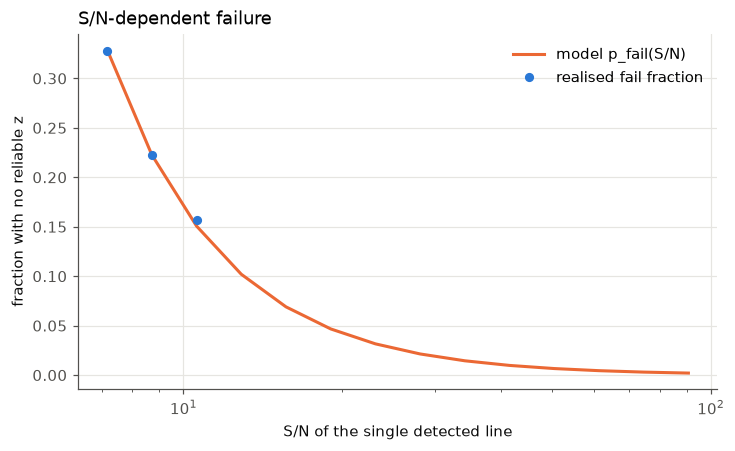

In [5]:
from romanmock.confusion import ConfusionMatrix, CONFUSION_MODELS, FAIL, build_confusion
from romanmock import assign_redshifts, IdOutcome


class SNRDependentConfusion:
    """p_fail(S/N) = p0 * (snr_ref / snr)^k, applied on top of a base matrix without fail."""

    def __init__(self, line_set, base_rows, p0=0.5, snr_ref=6.5, k=2.0):
        self.base = ConfusionMatrix.from_dict(line_set, base_rows)   # base matrix, rows sum to 1
        self.names = self.base.names
        self.p0, self.snr_ref, self.k = p0, snr_ref, k

    def p_fail(self, snr):
        return np.clip(self.p0 * (self.snr_ref / np.maximum(snr, 1e-3)) ** self.k, 0, 1)

    def assign(self, true_index, context, rng):
        j = self.base.assign(true_index, context, rng)
        fail = rng.random(len(j)) < self.p_fail(np.asarray(context["snr"]))
        return np.where(fail, FAIL, j)


CONFUSION_MODELS["snr_dependent"] = SNRDependentConfusion
model = build_confusion({"type": "snr_dependent", "base_rows": {"Ha": {"OIII_5007": 0.05}}, "p0": 0.4}, line_set)

det = detect_lines(flux, z_rsd, line_set, ThresholdDetection(ConstantFluxLimit()), rng)   # package default limit
za = assign_redshifts(det, z_rsd, line_set, model, rng)
single = det.n_det == 1
snr = det.snr[np.arange(len(z_rsd)), np.maximum(za.line_true, 0)][single]
failed = (za.outcome == IdOutcome.SINGLE_FAILED)[single]
bins = np.logspace(np.log10(6.5), 2, 15)
idx = np.digitize(snr, bins)
frac = np.array([failed[idx == b].mean() if np.any(idx == b) else np.nan for b in range(1, len(bins))])
fig, ax = plt.subplots()
xc = np.sqrt(bins[1:] * bins[:-1])
ax.plot(xc, model.p_fail(xc), color=plotting.CATEGORICAL[1], label="model p_fail(S/N)")
ax.plot(xc, frac, "o", color=plotting.CATEGORICAL[0], label="realised fail fraction")
ax.set_xscale("log"); ax.set_xlabel("S/N of the single detected line"); ax.set_ylabel("fraction with no reliable z")
ax.set_title("S/N-dependent failure"); ax.legend(); plt.show()

## Custom line sets

Bit ordering is whatever the `LineSet` says. A custom set can be given as a list of dicts (also in
YAML under `line_set:`); blends are sums of columns. Existing presets should never be reordered.

In [6]:
from romanmock.lines import LineSet, LineFeature

custom = LineSet.from_config([
    {"name": "Ha",   "components": ["Ba_alpha_6563"]},                                    # rest_wave from the built-in table
    {"name": "OIII", "components": ["O_III_4959", "O_III_5007"], "rest_wave": 5008.314},
    {"name": "OII",  "components": ["O_II_3726", "O_II_3729"], "rest_wave": 3728.6},
], name="three_features")
print(custom.describe())

from romanmock import RomanMockConfig
cfg = RomanMockConfig.from_dict({"line_set": custom.to_config(), "confusion": {"type": "identity", "p_fail": 0.05}})
print(cfg.to_yaml()[:600])

LineSet 'three_features': bit -> feature (rest wavelength [A]; components)
  bit  0 (value          1): Ha          6564.723  Ba_alpha_6563  
  bit  1 (value          2): OIII        5008.314  O_III_4959+O_III_5007  
  bit  2 (value          4): OII         3728.600  O_II_3726+O_II_3729  
catalog:
  path: ''
  files: null
  steps: null
  z_min: null
  z_max: null
  open_kwargs:
    synth_cores: false
    keep_top_host: true
  rest_waves_from_catalog: true
output:
  dir: ''
  tag: romanmock
  overwrite: false
  keep_undetected: false
  passthrough_columns:
  - ra
  - dec
  - redshift_true
  store_identification: true
  store_fluxes: false
  store_wave_obs: false
  store_snr: false
  store_measured_flux: false
  sample_columns:
  - ra
  - dec
  - redshift_true
  - redshift_rsd
  - redshift_assigned
  - id_outcome
line_set:
- name: Ha
  rest_wave: 6564.723
  components:
  - Ba_alp
